<a href="https://colab.research.google.com/github/pazolka/ai-climate-workshop-dhaka/blob/main/3.%20Modelling%20groundwater%20storage%20changes/GWSA_CNN_Bangladesh.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!git clone https://github.com/pazolka/ai-climate-workshop-dhaka.git
!pip install rioxarray

import sys
sys.path.append('/content/ai-climate-workshop-dhaka/3. Modelling groundwater storage changes')

# Modelling groundwater storage changes

with Convolutional Neural Networks (CNN)

Bangladesh has one of the most extensive groundwater monitoring networks in the world. This creates a unique opportunity to develop data-driven models that can map groundwater in unobserved areas and at future times and support sustainable resource management.

Here, we looking into mapping monthly groundwater storage anomalies (GWSA), derived from in-situ well measurements, from widely available satellite-derived covariates (NDVI, precipitation, evapotranspiration, GRACE terrestrial water storage, elevation). We train two different image-processing deep learning models: convolutional neural networks. First one is a **2D Unet**, which sees each month independently. **3D UNet** is an extension, as it ingests a short sequence of months ending at the target month.

<p align="center">
<img src="gwsa_definition.png" alt="task" width="500"/>
</p>

<img src="task_diagram.png" alt="task" width="1000"/>

In [20]:
# importing libraries

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'   # quiet TensorFlow's startup logs

import warnings
warnings.filterwarnings('ignore', message='.*Google will stop supporting.*')

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import geopandas as gpd
import rioxarray  # registers the .rio accessor

import keras
keras.utils.set_random_seed(0)

import models as md
import helpers as hlp

#### 1. Prepare the data

In [ ]:
# Step 1: Read the data
gwsa_incomplete = xr.open_dataset('ai-climate-workshop-dhaka/data/gridded/GWSA_M_2002_2017_BGD_025.nc')['gwsa']

# the elevation is static, so drop its single time step
dem = xr.open_dataset('ai-climate-workshop-dhaka/data/gridded/DEM_BGD_025.nc4')['dem'].squeeze('time', drop=True)

ndvi = xr.open_dataset('ai-climate-workshop-dhaka/data/gridded/NDVI_M_2002_2017_BGD_025.nc4')['NDVI']
terraclim = xr.open_dataset('ai-climate-workshop-dhaka/data/gridded/PR_AET_M_2002_2017_BGD_025.nc4')
pr = terraclim['pr']
aet = terraclim['aet']
twsa = xr.open_dataset('ai-climate-workshop-dhaka/data/gridded/TWSA_M_2002_2017_BGD_025.nc4')['twsa']

bgd_shp = gpd.read_file('ai-climate-workshop-dhaka/data/BGD_shp/Bangladesh.shp')

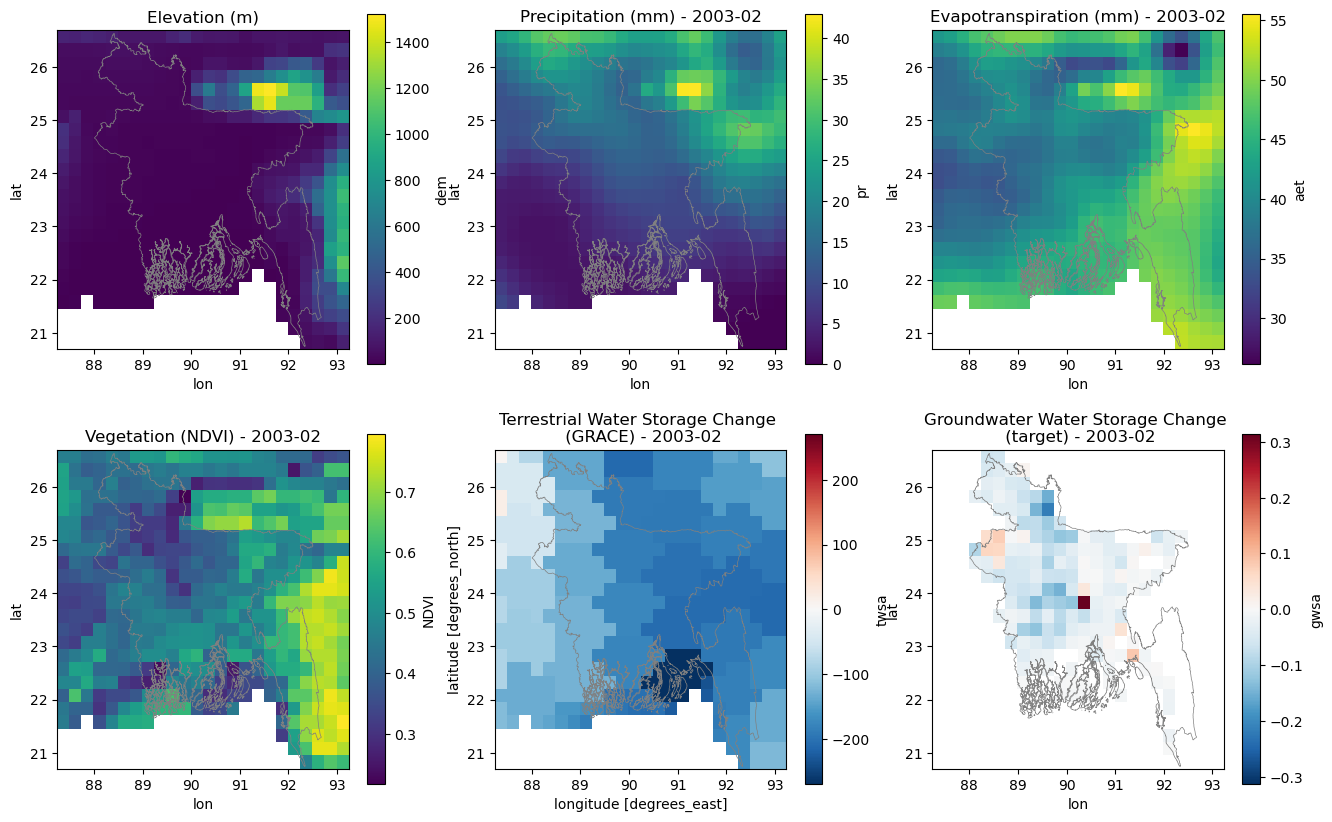

In [5]:
# Visualise
fig, axs = plt.subplots(figsize=(16, 10), nrows = 2, ncols = 3)
t=10
month = pd.Timestamp(pr.time[t].values).strftime('%Y-%m')
dem.plot(ax=axs[0,0])
axs[0,0].set_title('Elevation (m)')

pr[t].plot(ax=axs[0,1])
axs[0,1].set_title(f'Precipitation (mm) - {month}')

aet[t].plot(ax=axs[0,2])
axs[0,2].set_title(f'Evapotranspiration (mm) - {month}')

ndvi[t].plot(ax=axs[1,0])
axs[1,0].set_title(f'Vegetation (NDVI) - {month}')

twsa[t].plot(ax=axs[1,1])
axs[1,1].set_title(f'Terrestrial Water Storage Change \n (GRACE) - {month}')

gwsa_incomplete[t].plot(ax=axs[1,2])
axs[1,2].set_title(f'Groundwater Water Storage Change \n (target) - {month}')

for ax in axs.flatten():
    bgd_shp.boundary.plot(color='gray', linewidth=0.5, ax=ax)

We are working on gap-filled, quality checked well data that were rasterised into a grid (translated from a point location to a grid cell), and converted from level changes to storage changes (GWSA).

To make sure that our models work as expected, we need to manipulate our data in the following way:

- **Train/validation/test splitting.** The dataset is split in time, 80 % / 10 % / 10 %. so the model is trained on 80% of the data, with a parallel validation on 10%. Test data (final 10%) is where model is evaluated and assessed.

- **Spatial holdout.** Our task is to fill gaps in GWSA maps across time. Some wells were not used to generate the initial incomplete GWSA grid, and they are set aside to evaluate how well the model can predict GWSA at data from locations unseen before. 

- **Scaling.** Each covariate has different units and different magnitudes. We apply covariate scaling to each variable to bring very different units (NDVI, mm/month, metres) onto comparable scales. Also, target GWSA is scaled to [0,1] as well, but invalid pixels (outside of Bangladesh land area) are set to -1. *Note: scaling is only done based on the training months!*

- **Masking.** GWSA is only defined on the same 172 cells in every month, so one
  spatial mask is used for the model learning and in the validation metrics. This tells the model to learn only from the pixels where the target GWSA is defined. We treat pixels outside of the interest domain separately (set to -1 and ignored).

![temp_split](time_split.png)

In [6]:
# Step 2: split the record in time (80 / 10 / 10)
times = pd.to_datetime(ndvi.time.values)

n = len(times)
n_train, n_val = int(0.8 * n), int(0.1 * n)
train_idx = np.arange(0, n_train)
val_idx = np.arange(n_train, n_train + n_val)
test_idx = np.arange(n_train + n_val, n)

# Step 3: scale the covariates (fit on the training months)
covariates = [dem, ndvi, pr, aet, twsa]
covariates = hlp.scale_covariates(covariates, times[train_idx])
cov_stack = hlp.stack_covariates(covariates, times)

X = cov_stack.values.copy()
X[np.isnan(X)] = -1.0                      # fill value

# scale the target with the training min/max, then fill gaps with -1
y = gwsa_incomplete.values                 # (time, lat, lon)
y_min = np.nanmin(y[train_idx])
y_max = np.nanmax(y[train_idx])
Y = (y - y_min) / (y_max - y_min)
Y = np.where(np.isfinite(Y), Y, -1.0)[..., np.newaxis]

print(f'train {len(train_idx)} | validation {len(val_idx)} | test {len(test_idx)} months')
print(f'target range: {y_min:.3f} .. {y_max:.3f}')

# Step 4: find the valid training pixels mask
valid2d = np.isfinite(y).all(axis=0)       # fixed spatial mask (ocean / no data)
print(f'covariates: {X.shape} | target: {y.shape} | valid cells: {valid2d.sum()}')

train 145 | validation 18 | test 19 months
target range: -0.592 .. 0.436
covariates: (182, 24, 24, 5) | target: (182, 24, 24) | valid cells: 172


### 2. Spatial only (2D) UNet: one map in, one map out

Each month is an independent example, so the model can only learn a static relationship between the covariates and GWSA - useful for capturing spatial patterns, but it's blind to temporal memory. The loss function that the model uses for training is a masked MSE.

In [21]:
# Step 5.1: build and compile the 2D UNet
model2d = md.Unet2D(X.shape[1:])           # (lat, lon, covariates)
model2d.compile(
    optimizer='adam',
    loss=md.make_masked_mse_loss(valid2d),
    metrics=[md.masked_r2],
)
#model2d.summary()

In [22]:
# Step 5.2: train
history2d = model2d.fit(
    X[train_idx], Y[train_idx],
    validation_data=(X[val_idx], Y[val_idx]), # validation data is used to monitor the training progress and prevent overfitting
    epochs=80,
    batch_size=10,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)], # interrupt training if validation loss does not improve for 15 epochs
    verbose=0
)

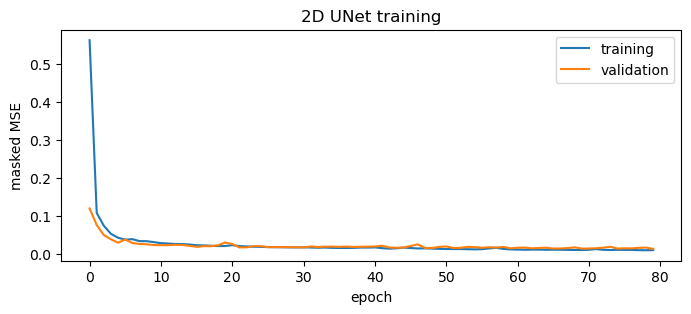

In [23]:
# learning curves
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(history2d.history['loss'], label='training')
ax.plot(history2d.history['val_loss'], label='validation')
ax.set(xlabel='epoch', ylabel='masked MSE', title='2D UNet training')
ax.legend()
plt.show()

Training and validation loss fall steeply over the first ~10 epochs and then flatten, with validation staying close to the training curve. This means that the training is healthy and there is no sign of overfitting.

                  n   rmse     r2
train       24940.0  0.031  0.867
validation   3096.0  0.041  0.754
test         3268.0  0.042  0.741


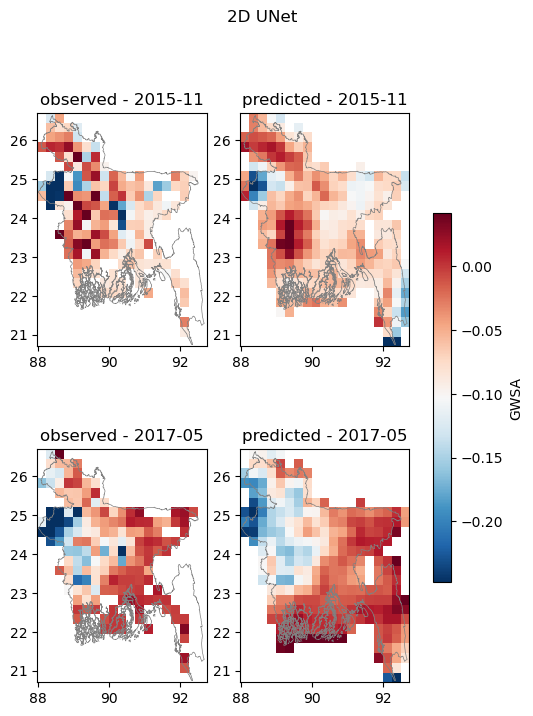

In [24]:
# Step 5.3: predict every month, convert back to the original units and score
pred2d = model2d.predict(X, batch_size=5, verbose=0)[..., 0]
pred2d = pred2d * (y_max - y_min) + y_min

scores2d = pd.DataFrame({
    'train': hlp.masked_scores(y[train_idx], pred2d[train_idx]),
    'validation': hlp.masked_scores(y[val_idx], pred2d[val_idx]),
    'test': hlp.masked_scores(y[test_idx], pred2d[test_idx]),
}).T
print(scores2d.round(3))

# visualise maps for two test months
hlp.plot_maps(y, gwsa_incomplete, pred2d, bgd_shp, times, test_idx[[0, -1]], '2D UNet')

### 3. Spatiotemporal (3D) UNet: a sequence of maps in, one map out

Instead of one month, each sample is the last `lag = 3` months of covariates, so the model learns over time as well as space.

In [25]:
# Step 6.1: extend the input data into lag-month sequences
lag = 3
X3 = np.stack([X[i - lag + 1:i + 1] for i in range(lag - 1, n)], axis=0)
Y3 = Y[lag - 1:]                           # target month = last month of each sequence
times3 = times[lag - 1:]

n3 = len(Y3)
n3_train, n3_val = int(0.8 * n3), int(0.1 * n3)
train3 = np.arange(0, n3_train)
val3 = np.arange(n3_train, n3_train + n3_val)
test3 = np.arange(n3_train + n3_val, n3)

print(f'sequences: {X3.shape} | targets: {Y3.shape}')

sequences: (180, 3, 24, 24, 5) | targets: (180, 24, 24, 1)


In [26]:
# Step 6.2: build and compile the 3D UNet
model3d = md.UNet3D(X3.shape[1:])          # (lag, lat, lon, covariates)
model3d.compile(
    optimizer='adam',
    loss=md.make_masked_mse_with_trend(valid2d),
    metrics=[md.masked_r2],
)
#model3d.summary()

In [ ]:
# Step 6.3: train
history3d = model3d.fit(
    X3[train3], Y3[train3],
    validation_data=(X3[val3], Y3[val3]), # validation data is used to monitor the training progress and prevent overfitting
    epochs=50,
    batch_size=10,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)], # interrupt training if validation loss does not improve for 15 epochs
    verbose=0,
)

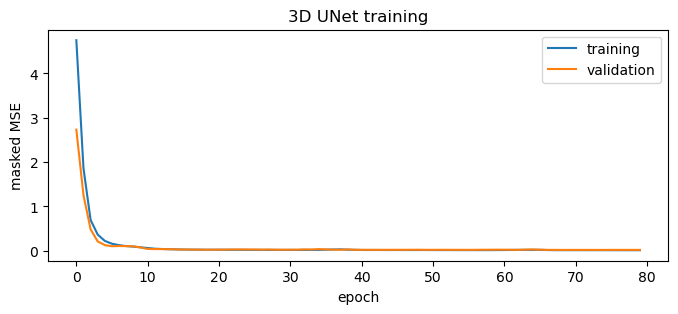

In [28]:
# learning curves
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(history3d.history['loss'], label='training')
ax.plot(history3d.history['val_loss'], label='validation')
ax.set(xlabel='epoch', ylabel='masked MSE', title='3D UNet training')
ax.legend()
plt.show()

                  n   rmse     r2
train       24768.0  0.035  0.835
validation   3096.0  0.046  0.655
test         3096.0  0.046  0.695


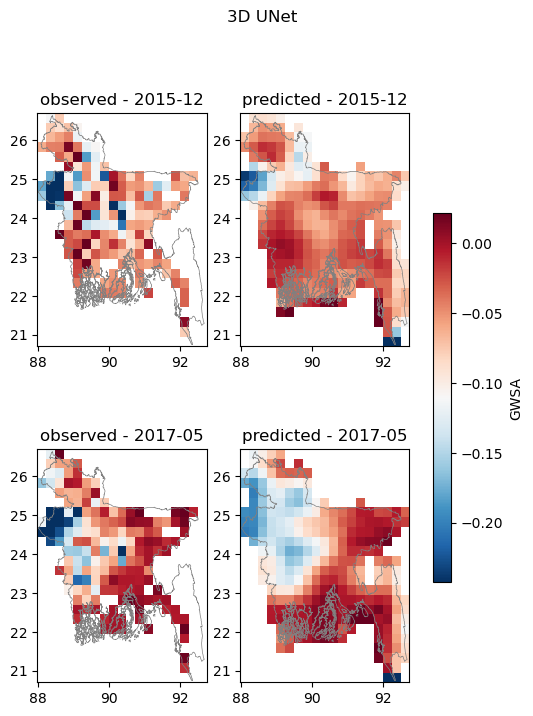

In [29]:
# Step 6.4: predict, denormalise and score
pred3d = model3d.predict(X3, batch_size=5, verbose=0)[..., 0]
pred3d = pred3d * (y_max - y_min) + y_min
y3 = y[lag - 1:]

scores3d = pd.DataFrame({
    'train': hlp.masked_scores(y3[train3], pred3d[train3]),
    'validation': hlp.masked_scores(y3[val3], pred3d[val3]),
    'test': hlp.masked_scores(y3[test3], pred3d[test3]),
}).T
print(scores3d.round(3))

hlp.plot_maps(y3, gwsa_incomplete, pred3d, bgd_shp, times3, test3[[0, -1]], '3D UNet')

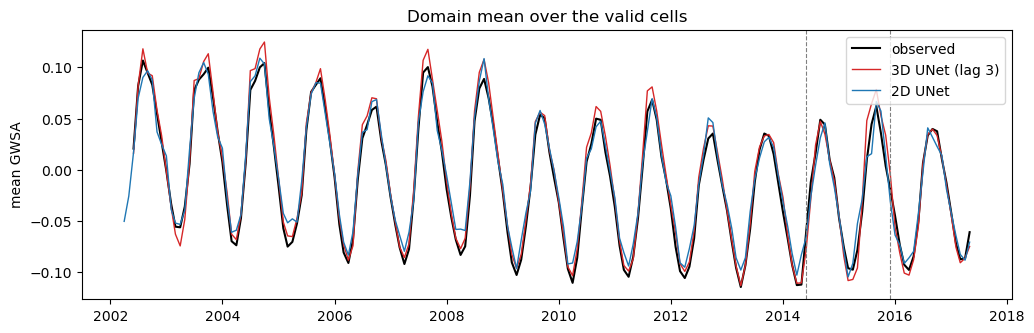

In [30]:
# Step 7: domain-mean time series

def domain_mean(field):
    return np.array([np.nanmean(field[i][valid2d]) for i in range(len(field))])

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(times3, domain_mean(y3), color='black', label='observed')
ax.plot(times3, domain_mean(pred3d), color='tab:red', lw=1, label=f'3D UNet (lag {lag})')
ax.plot(times, domain_mean(pred2d), color='tab:blue', lw=1, label='2D UNet')
for x in (times3[n3_train], times3[n3_train + n3_val]):
    ax.axvline(x, color='gray', ls='--', lw=0.8)
ax.set(ylabel='mean GWSA', title='Domain mean over the valid cells')
ax.legend()
plt.show()

We can see that both models have their biases: 2D Unet tends to overestimate dry-season GWSA on the country scale, while 3D Unet overestimates GWSA in wet season. However, the performance is still very strong in terms of R2 and RMSE. Including lagged covariates doesn't improve the performance, as groundwater response to precipitation in Bangladesh is typically rapid. 

### 4. Evaluation across space and time

There are two independent ways to test the models:

- **test time (grid cells)** - months the model never saw (test times), scored against the gridded target; this measures temporal extrapolation.

- **train time at held-out locations** - months the model did see, but at wells that never contributed to the grid (spatial test hold-out); this measures spatial generalisation.


In [ ]:
# Step 8: held-out wells, converted from GWL to GWSA
obs = hlp.load_gwl_observations(
    'ai-climate-workshop-dhaka/data/point_observations/BWDB_gwl_ts_monthly_filled.csv',
    'ai-climate-workshop-dhaka/data/point_observations/BWDB_gwl_station_info.csv')

In [31]:
# Step 9: test time on grid cells, train time at held-out wells
cross = hlp.cross_split_table({
    '2D UNet': (pred2d, times, y, times[train_idx], times[test_idx]),
    '3D UNet': (pred3d, times3, y3, times3[train3], times3[test3]),
}, obs, gwsa_incomplete.lat, gwsa_incomplete.lon)
cross.round(3)

task    test time (grid cells)               train time @ held-out wells  \
metric                       n   rmse     r2                           n   
model                                                                      
2D UNet                 3268.0  0.042  0.741                       427.0   
3D UNet                 3096.0  0.046  0.695                       420.0   

task                   
metric    rmse     r2  
model                  
2D UNet  0.148  0.402  
3D UNet  0.149  0.396

### Summary

- The **2D UNet** learns a static map from covariates to GWSA. It captures the spatial
  pattern but treats every month independently, so it cannot carry memory of previous
  months.
- The **3D UNet** sees the last `lag = 3` months. In Bangladesh, adding lagged covariates doesn't improve the performance, as the groundwater response to precipitation is rapid, and the computational cost rises substantially.
- Both models are trained on a single 80/10/10 train/validation/test split of a small (182-month, 24×24 grid) dataset.

- Evaluating the two axes separately: at **test time on training locations** (temporal extrapolation) and at **train time on the held-out locations** (spatial generalisation), the 2D model remains closer to the observations than the 3D model.